## 1: Environment Setup, Loading Preprocessed Data & Partition Verification

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Metrics for imbalanced evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    f1_score,
    fbeta_score
)

# 1. Resolve data directory (handles repo root or notebooks/ working directory)
data_dir = 'data' if os.path.exists('data/train_data.csv') else '../data'
train_path = os.path.join(data_dir, 'train_data.csv')
test_path = os.path.join(data_dir, 'test_data.csv')

# 2. Load preprocessed datasets
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

# 3. Separate features and target
X_train = train_df.drop(columns=['Class'])
y_train = train_df['Class']

X_test = test_df.drop(columns=['Class'])
y_test = test_df['Class']

# 4. Display partition verification summary
print("=" * 65)
print(" DATASETS LOADED & VERIFIED")
print("=" * 65)
print(f"X_train shape: {X_train.shape} | y_train: {y_train.sum()} fraud cases ({y_train.mean()*100:.3f}%)")
print(f"X_test shape:  {X_test.shape}  | y_test:  {y_test.sum()} fraud cases ({y_test.mean()*100:.3f}%)")
print(f"Missing values in Train: {X_train.isnull().sum().sum()}")
print(f"Missing values in Test:  {X_test.isnull().sum().sum()}")
print("=" * 65)

# Preview first 5 rows
X_train.head()

 DATASETS LOADED & VERIFIED
X_train shape: (226980, 30) | y_train: 378 fraud cases (0.167%)
X_test shape:  (56746, 30)  | y_test:  95 fraud cases (0.167%)
Missing values in Train: 0
Missing values in Test:  0


,Amount,Time,V1,V2,V3,V4,V5,V6,V7,V8,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
0,0.137472,0.701730,2.238954,-1.724499,-2.151484,-2.577803,0.993668,3.565492,-1.785957,0.860122,...,-0.318110,-0.323810,-0.149574,-0.049333,0.278442,0.684735,-0.219028,-0.159167,0.037920,-0.049932
1,-0.209119,-0.048166,-1.315062,1.630783,0.597001,-0.038359,-0.404580,-0.965712,0.212249,0.735381,...,0.392417,-0.067580,-0.238898,-0.946773,0.323904,0.515632,-0.713000,-0.266503,-0.017794,0.051058
2,-0.098808,0.496931,1.908801,0.021184,-2.087997,0.129310,1.161468,0.605244,-0.022371,0.180296,...,-0.994654,-0.210474,0.293609,1.095842,-0.044874,-1.689517,0.106098,0.007758,0.045164,-0.053068
3,-0.066242,0.076666,1.811257,0.316556,0.316751,3.880231,0.048454,1.020163,-0.734868,0.233651,...,-1.693484,-0.228032,0.138869,0.700422,0.174064,0.702997,-0.212523,-0.010018,-0.017740,-0.038006
4,0.026608,-0.649581,1.358817,-1.120881,0.550266,-1.547659,-1.194950,0.275448,-1.201843,0.212889,...,-0.591751,-0.361686,-0.340972,-0.636442,0.252758,-0.344160,-0.064282,-0.439622,0.062524,0.013095


## 2: Standardized Evaluation Helper & Leaderboard Registry

In [2]:
# Leaderboard dictionary to track and compare all models
leaderboard = {}

def evaluate_fraud_model(model_name, model, X_test, y_test, threshold=0.5):
    """
    Standardized evaluation function for fraud detection models.
    Computes PR-AUC, ROC-AUC, Precision, Recall, F1, F2 and plots:
    1. Confusion Matrix
    2. Precision-Recall Curve (with baseline)
    3. ROC Curve
    """
    # 1. Generate predicted probabilities and binary predictions at threshold
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    # 2. Compute key metrics
    pr_auc = average_precision_score(y_test, y_prob)
    roc_auc = roc_auc_score(y_test, y_prob)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    f2 = fbeta_score(y_test, y_pred, beta=2, zero_division=0)
    
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    # 3. Register to global leaderboard
    leaderboard[model_name] = {
        'PR-AUC': round(pr_auc, 4),
        'ROC-AUC': round(roc_auc, 4),
        'Recall (Fraud)': round(recall, 4),
        'Precision (Fraud)': round(precision, 4),
        'F1-Score': round(f1, 4),
        'F2-Score': round(f2, 4),
        'Caught Fraud (TP)': int(tp),
        'Missed Fraud (FN)': int(fn),
        'False Alarms (FP)': int(fp)
    }

    # 4. Print structured summary report
    print("=" * 65)
    print(f" EVALUATION REPORT: {model_name.upper()} (Threshold = {threshold})")
    print("=" * 65)
    print(f"PR-AUC (Average Precision): {pr_auc:.4f}  |  ROC-AUC: {roc_auc:.4f}")
    print(f"Recall (Frauds Caught):    {recall:.2%} ({tp}/{tp + fn})")
    print(f"Precision:                 {precision:.2%} ({tp}/{tp + fp})")
    print(f"F1-Score: {f1:.4f}          |  F2-Score (Recall Priority): {f2:.4f}")
    print(f"Missed Frauds (FN): {fn}   |  False Alarms (FP): {fp}")
    print("=" * 65)

    # 5. Diagnostic Visualizations (3-panel)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Panel A: Confusion Matrix Heatmap
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
                xticklabels=['Legit (0)', 'Fraud (1)'],
                yticklabels=['Legit (0)', 'Fraud (1)'])
    axes[0].set_title(f"Confusion Matrix: {model_name}", fontweight='bold')
    axes[0].set_ylabel("Actual Label")
    axes[0].set_xlabel("Predicted Label")

    # Panel B: Precision-Recall Curve
    p_curve, r_curve, _ = precision_recall_curve(y_test, y_prob)
    baseline = y_test.mean()
    axes[1].plot(r_curve, p_curve, color='#d9534f', linewidth=2, label=f"PR-AUC = {pr_auc:.4f}")
    axes[1].axhline(y=baseline, color='navy', linestyle='--', label=f"Baseline ({baseline:.3%})")
    axes[1].set_title("Precision-Recall Curve", fontweight='bold')
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_ylim([-0.05, 1.05])
    axes[1].legend(loc='lower left')
    axes[1].grid(True, linestyle=':', alpha=0.6)

    # Panel C: ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[2].plot(fpr, tpr, color='#2b5c8f', linewidth=2, label=f"ROC-AUC = {roc_auc:.4f}")
    axes[2].plot([0, 1], [0, 1], color='gray', linestyle='--')
    axes[2].set_title("Receiver Operating Characteristic (ROC)", fontweight='bold')
    axes[2].set_xlabel("False Positive Rate")
    axes[2].set_ylabel("True Positive Rate (Recall)")
    axes[2].legend(loc='lower right')
    axes[2].grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

    return y_prob

print("Evaluation framework initialized successfully.")

Evaluation framework initialized successfully.


## 3: Baseline Model - Logistic Regression (Unweighted)

Training Baseline Logistic Regression...
 EVALUATION REPORT: BASELINE LOGISTIC REGRESSION (Threshold = 0.5)
PR-AUC (Average Precision): 0.6951  |  ROC-AUC: 0.9575
Recall (Frauds Caught):    58.95% (56/95)
Precision:                 86.15% (56/65)
F1-Score: 0.7000          |  F2-Score (Recall Priority): 0.6292
Missed Frauds (FN): 39   |  False Alarms (FP): 9


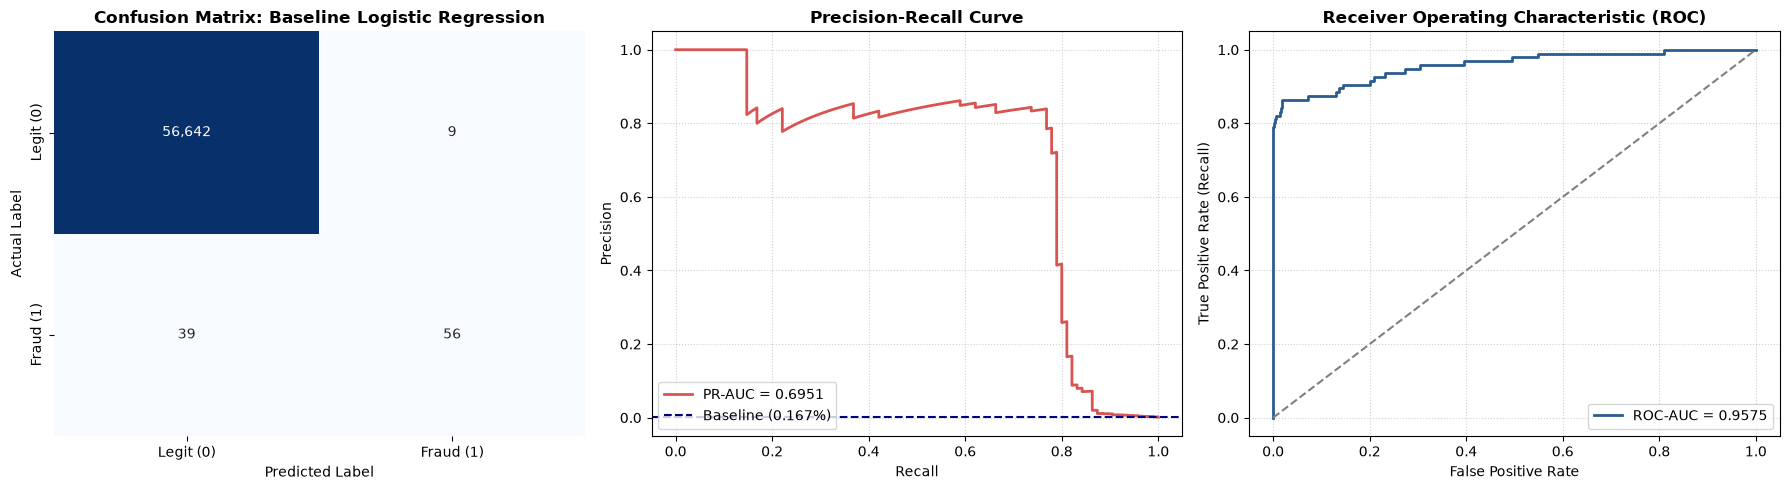

In [3]:
from sklearn.linear_model import LogisticRegression

# 1. Instantiate standard Logistic Regression (unweighted)
lr_base = LogisticRegression(max_iter=1000, random_state=42)

# 2. Train on the preprocessed training set
print("Training Baseline Logistic Regression...")
lr_base.fit(X_train, y_train)

# 3. Evaluate using our standardized framework
y_prob_lr_base = evaluate_fraud_model(
    model_name="Baseline Logistic Regression",
    model=lr_base,
    X_test=X_test,
    y_test=y_test,
    threshold=0.5
)

## 4: Cost-Sensitive Logistic Regression (`class_weight='balanced'`)

Training Balanced (Cost-Sensitive) Logistic Regression...
 EVALUATION REPORT: BALANCED LOGISTIC REGRESSION (Threshold = 0.5)
PR-AUC (Average Precision): 0.6719  |  ROC-AUC: 0.9657
Recall (Frauds Caught):    87.37% (83/95)
Precision:                 5.62% (83/1476)
F1-Score: 0.1057          |  F2-Score (Recall Priority): 0.2236
Missed Frauds (FN): 12   |  False Alarms (FP): 1393


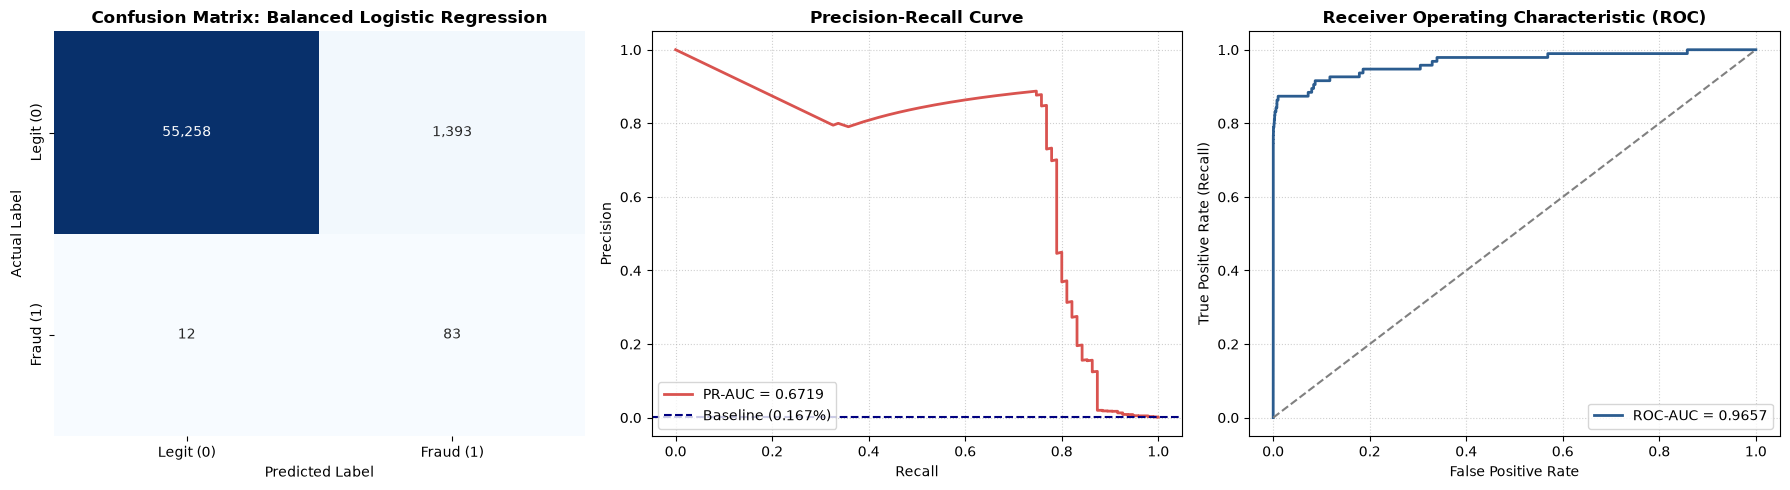

In [4]:
# 1. Instantiate Logistic Regression with balanced class weights
lr_balanced = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# 2. Train on the preprocessed training set
print("Training Balanced (Cost-Sensitive) Logistic Regression...")
lr_balanced.fit(X_train, y_train)

# 3. Evaluate using our standardized framework
y_prob_lr_balanced = evaluate_fraud_model(
    model_name="Balanced Logistic Regression",
    model=lr_balanced,
    X_test=X_test,
    y_test=y_test,
    threshold=0.5
)

## 5: Non-Linear Ensemble - Random Forest Classifier

Training Balanced Random Forest Classifier (this may take ~10-15 seconds)...
 EVALUATION REPORT: RANDOM FOREST (Threshold = 0.5)
PR-AUC (Average Precision): 0.7919  |  ROC-AUC: 0.9578
Recall (Frauds Caught):    74.74% (71/95)
Precision:                 84.52% (71/84)
F1-Score: 0.7933          |  F2-Score (Recall Priority): 0.7651
Missed Frauds (FN): 24   |  False Alarms (FP): 13


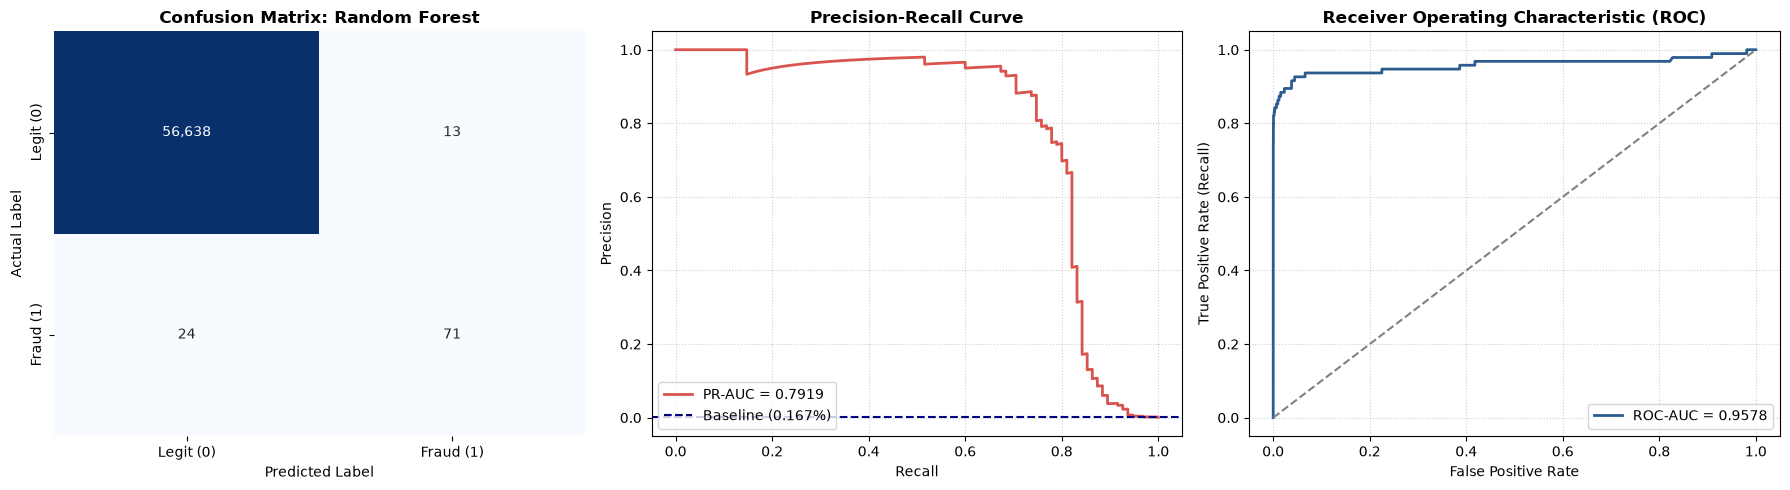

In [5]:
from sklearn.ensemble import RandomForestClassifier

# 1. Instantiate Random Forest with balanced weighting and controlled depth
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# 2. Train on the preprocessed training set
print("Training Balanced Random Forest Classifier (this may take ~10-15 seconds)...")
rf_clf.fit(X_train, y_train)

# 3. Evaluate using our standardized framework
y_prob_rf = evaluate_fraud_model(
    model_name="Random Forest",
    model=rf_clf,
    X_test=X_test,
    y_test=y_test,
    threshold=0.5
)

## 6: Gradient Boosted Trees - XGBoost with Cost-Weighting

XGBoost scale_pos_weight set to: 599.48
Training XGBoost Classifier...
 EVALUATION REPORT: XGBOOST (Threshold = 0.5)
PR-AUC (Average Precision): 0.8209  |  ROC-AUC: 0.9766
Recall (Frauds Caught):    81.05% (77/95)
Precision:                 86.52% (77/89)
F1-Score: 0.8370          |  F2-Score (Recall Priority): 0.8209
Missed Frauds (FN): 18   |  False Alarms (FP): 12


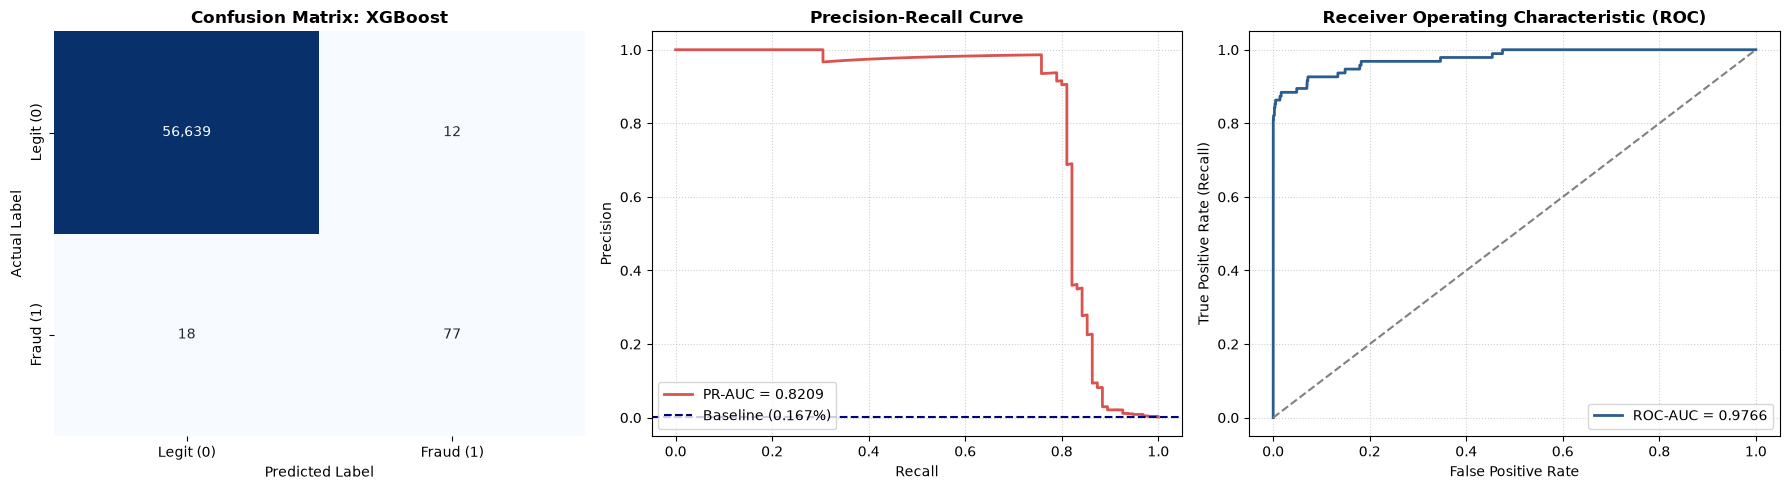

In [6]:
import xgboost as xgb

# 1. Compute exact class imbalance ratio for scale_pos_weight
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"XGBoost scale_pos_weight set to: {imbalance_ratio:.2f}")

# 2. Instantiate XGBoost Classifier
xgb_clf = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=imbalance_ratio,
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1
)

# 3. Train on the preprocessed training set
print("Training XGBoost Classifier...")
xgb_clf.fit(X_train, y_train)

# 4. Evaluate using our standardized framework
y_prob_xgb = evaluate_fraud_model(
    model_name="XGBoost",
    model=xgb_clf,
    X_test=X_test,
    y_test=y_test,
    threshold=0.5
)

## 7: Leaf-Wise Gradient Boosting - LightGBM Classifier

Training LightGBM Classifier...
 EVALUATION REPORT: LIGHTGBM (Threshold = 0.5)
PR-AUC (Average Precision): 0.0241  |  ROC-AUC: 0.8828
Recall (Frauds Caught):    81.05% (77/95)
Precision:                 2.94% (77/2620)
F1-Score: 0.0567          |  F2-Score (Recall Priority): 0.1283
Missed Frauds (FN): 18   |  False Alarms (FP): 2543


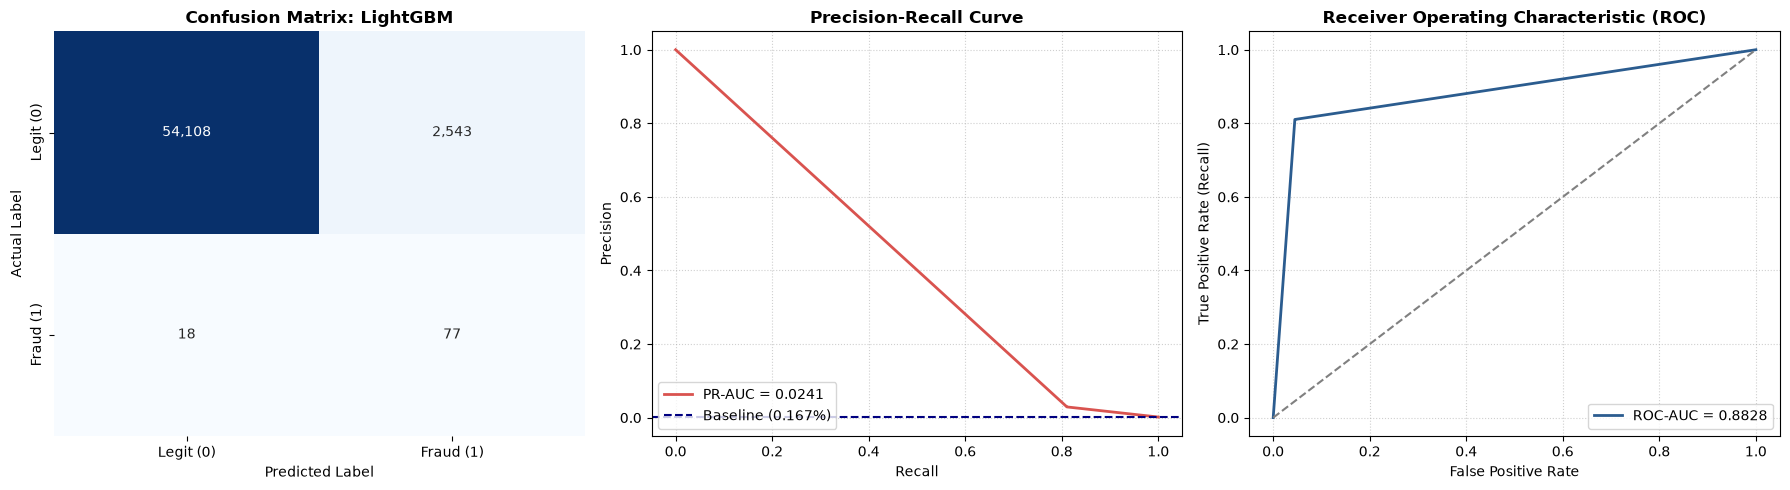

In [7]:
import lightgbm as lgb

# 1. Instantiate LightGBM with leaf-wise architecture and cost-weighting
lgb_clf = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.08,
    num_leaves=31,
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

# 2. Train on the preprocessed training set
print("Training LightGBM Classifier...")
lgb_clf.fit(X_train, y_train)

# 3. Evaluate using our standardized framework
y_prob_lgb = evaluate_fraud_model(
    model_name="LightGBM",
    model=lgb_clf,
    X_test=X_test,
    y_test=y_test,
    threshold=0.5
)

## 8: Symmetric Boosting - CatBoost Classifier

Training CatBoost Classifier (this may take ~15-20 seconds)...
 EVALUATION REPORT: CATBOOST (Threshold = 0.5)
PR-AUC (Average Precision): 0.8063  |  ROC-AUC: 0.9625
Recall (Frauds Caught):    78.95% (75/95)
Precision:                 78.12% (75/96)
F1-Score: 0.7853          |  F2-Score (Recall Priority): 0.7878
Missed Frauds (FN): 20   |  False Alarms (FP): 21


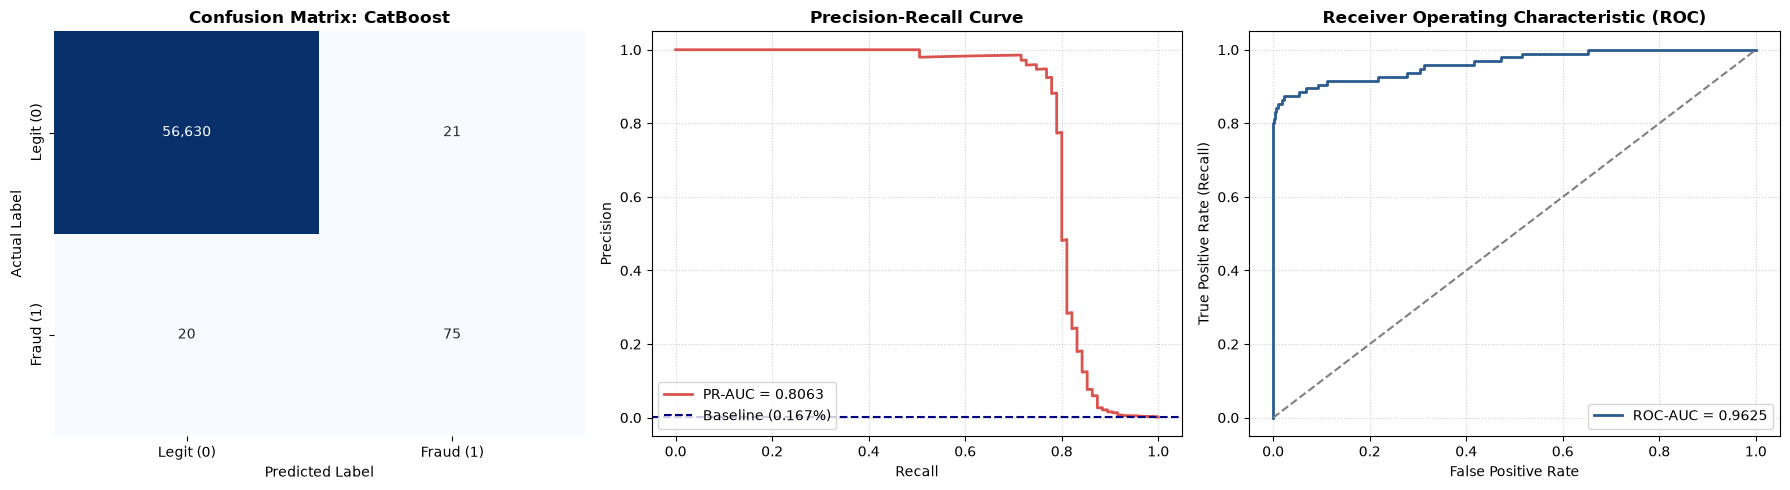

In [8]:
from catboost import CatBoostClassifier

# 1. Instantiate CatBoost with symmetric trees and balanced class weights
cb_clf = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.08,
    auto_class_weights='Balanced',
    eval_metric='PRAUC',
    random_seed=42,
    verbose=0
)

# 2. Train on the preprocessed training set
print("Training CatBoost Classifier (this may take ~15-20 seconds)...")
cb_clf.fit(X_train, y_train)

# 3. Evaluate using our standardized framework
y_prob_cb = evaluate_fraud_model(
    model_name="CatBoost",
    model=cb_clf,
    X_test=X_test,
    y_test=y_test,
    threshold=0.5
)

## 9: Comprehensive Model Leaderboard & Comparative Analysis

                   MODEL EVALUATION LEADERBOARD


,PR-AUC,ROC-AUC,Recall (Fraud),Precision (Fraud),F1-Score,F2-Score,Caught Fraud (TP),Missed Fraud (FN),False Alarms (FP)
XGBoost,0.8209,0.9766,0.8105,0.8652,0.8370,0.8209,77.0,18.0,12.0
CatBoost,0.8063,0.9625,0.7895,0.7812,0.7853,0.7878,75.0,20.0,21.0
Random Forest,0.7919,0.9578,0.7474,0.8452,0.7933,0.7651,71.0,24.0,13.0
Baseline Logistic Regression,0.6951,0.9575,0.5895,0.8615,0.7000,0.6292,56.0,39.0,9.0
Balanced Logistic Regression,0.6719,0.9657,0.8737,0.0562,0.1057,0.2236,83.0,12.0,1393.0
LightGBM,0.0241,0.8828,0.8105,0.0294,0.0567,0.1283,77.0,18.0,2543.0


C:\Users\Soham\AppData\Local\Temp\ipykernel_15804\946958682.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha='right')


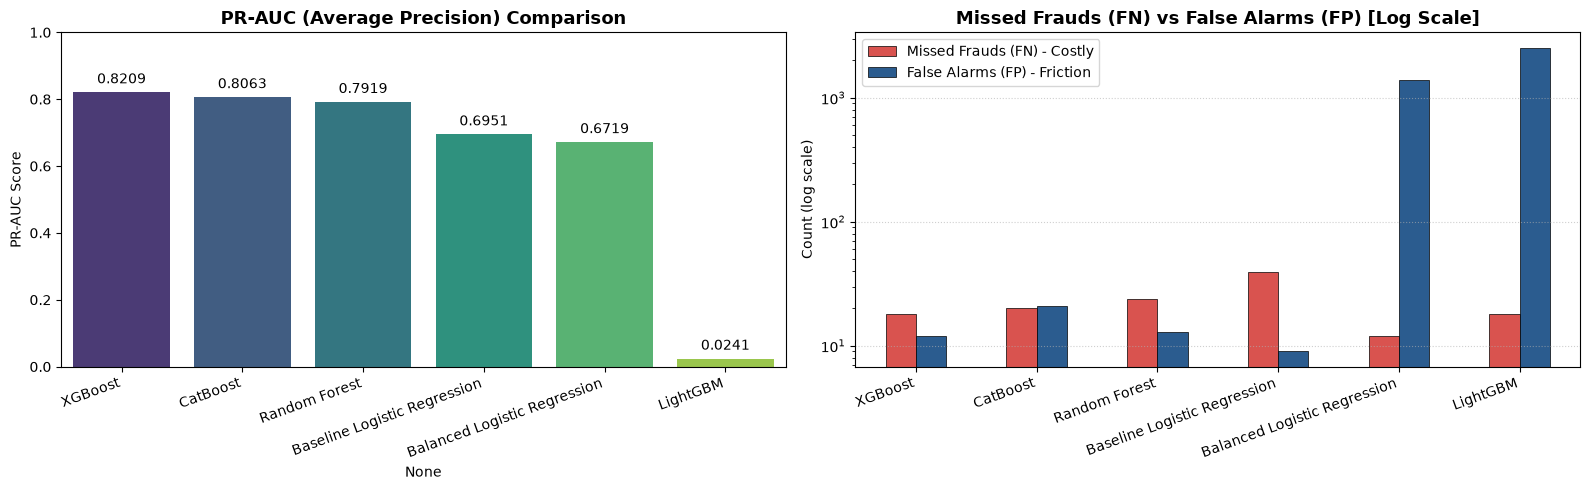


Champion Model by PR-AUC: XGBoost (PR-AUC: 0.8209)


In [9]:
# 1. Convert registered metrics dictionary into a styled DataFrame
leaderboard_df = pd.DataFrame(leaderboard).T
leaderboard_df = leaderboard_df.sort_values(by='PR-AUC', ascending=False)

print("=" * 75)
print("                   MODEL EVALUATION LEADERBOARD")
print("=" * 75)
display(leaderboard_df)

# 2. Comparative Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Metric 1: PR-AUC (Primary Metric)
sns.barplot(x=leaderboard_df.index, y=leaderboard_df['PR-AUC'], ax=axes[0], palette='viridis', hue=leaderboard_df.index, legend=False)
axes[0].set_title("PR-AUC (Average Precision) Comparison", fontsize=13, fontweight='bold')
axes[0].set_ylabel("PR-AUC Score")
axes[0].set_ylim(0, 1.0)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha='right')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')

# Metric 2: Error Trade-off: Missed Frauds (FN) vs False Alarms (FP)
error_df = leaderboard_df[['Missed Fraud (FN)', 'False Alarms (FP)']].copy()
# Log scale for false alarms visualization to handle large discrepancies
error_df.plot(kind='bar', ax=axes[1], color=['#d9534f', '#2b5c8f'], edgecolor='black', linewidth=0.5)
axes[1].set_yscale('log')
axes[1].set_title("Missed Frauds (FN) vs False Alarms (FP) [Log Scale]", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Count (log scale)")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right')
axes[1].legend(['Missed Frauds (FN) - Costly', 'False Alarms (FP) - Friction'])
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

champion_model_name = leaderboard_df.index[0]
print(f"\nChampion Model by PR-AUC: {champion_model_name} (PR-AUC: {leaderboard_df.loc[champion_model_name, 'PR-AUC']:.4f})")

## 10: Threshold Tuning & Financial Cost-Benefit Analysis (XGBoost)

             OPTIMAL DECISION THRESHOLDS (XGBOOST)
Max F1-Score:    Threshold = 0.798 | F1 = 0.8571 | Recall = 78.95% | Precision = 93.75%
Max F2-Score:    Threshold = 0.552 | F2 = 0.8280 | Recall = 81.05% | Precision = 90.59%
Min Dollar Cost: Threshold = 0.182 | Total Loss = $2,658.00 | Missed = 17 | FP = 36


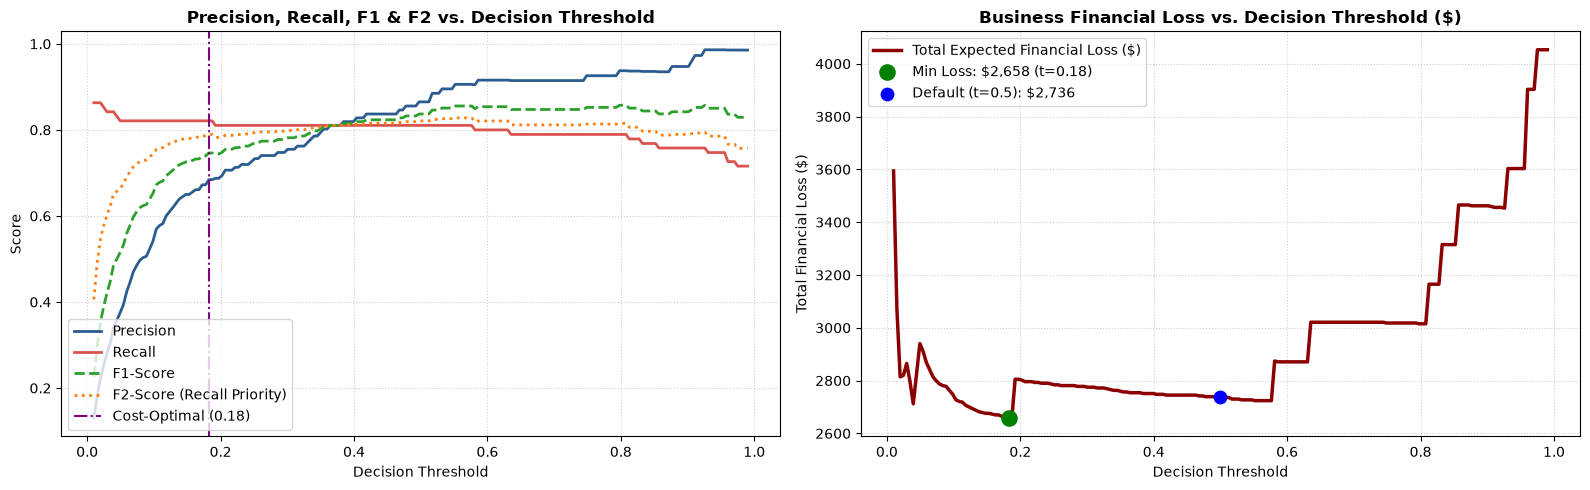

In [10]:
# 1. Define financial cost parameters
COST_FN = 150.0  # Average cost of an undetected fraud (chargeback + stolen funds)
COST_FP = 3.0    # Friction/investigation cost of a false alarm

thresholds = np.linspace(0.01, 0.99, 200)
results = []

for t in thresholds:
    preds = (y_prob_xgb >= t).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
    f2 = (5 * prec * rec) / (4 * prec + rec) if (4 * prec + rec) > 0 else 0.0
    total_cost = (fn * COST_FN) + (fp * COST_FP)
    
    results.append({
        'Threshold': t,
        'Precision': prec,
        'Recall': rec,
        'F1': f1,
        'F2': f2,
        'FN': fn,
        'FP': fp,
        'Total_Cost': total_cost
    })

thresh_df = pd.DataFrame(results)

# 2. Identify optimal operating points
best_f1_idx = thresh_df['F1'].idxmax()
best_f2_idx = thresh_df['F2'].idxmax()
best_cost_idx = thresh_df['Total_Cost'].idxmin()

opt_f1 = thresh_df.loc[best_f1_idx]
opt_f2 = thresh_df.loc[best_f2_idx]
opt_cost = thresh_df.loc[best_cost_idx]

print("=" * 70)
print("             OPTIMAL DECISION THRESHOLDS (XGBOOST)")
print("=" * 70)
print(f"Max F1-Score:    Threshold = {opt_f1['Threshold']:.3f} | F1 = {opt_f1['F1']:.4f} | Recall = {opt_f1['Recall']:.2%} | Precision = {opt_f1['Precision']:.2%}")
print(f"Max F2-Score:    Threshold = {opt_f2['Threshold']:.3f} | F2 = {opt_f2['F2']:.4f} | Recall = {opt_f2['Recall']:.2%} | Precision = {opt_f2['Precision']:.2%}")
print(f"Min Dollar Cost: Threshold = {opt_cost['Threshold']:.3f} | Total Loss = ${opt_cost['Total_Cost']:,.2f} | Missed = {int(opt_cost['FN'])} | FP = {int(opt_cost['FP'])}")
print("=" * 70)

# 3. Multi-Metric Threshold Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot A: Metric curves across thresholds
axes[0].plot(thresh_df['Threshold'], thresh_df['Precision'], label='Precision', color='#2b5c8f', linewidth=2)
axes[0].plot(thresh_df['Threshold'], thresh_df['Recall'], label='Recall', color='#d9534f', linewidth=2)
axes[0].plot(thresh_df['Threshold'], thresh_df['F1'], label='F1-Score', color='#2ca02c', linestyle='--', linewidth=2)
axes[0].plot(thresh_df['Threshold'], thresh_df['F2'], label='F2-Score (Recall Priority)', color='#ff7f0e', linestyle=':', linewidth=2)
axes[0].axvline(opt_cost['Threshold'], color='purple', linestyle='-.', label=f"Cost-Optimal ({opt_cost['Threshold']:.2f})")
axes[0].set_title("Precision, Recall, F1 & F2 vs. Decision Threshold", fontweight='bold')
axes[0].set_xlabel("Decision Threshold")
axes[0].set_ylabel("Score")
axes[0].legend(loc='lower left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot B: Total Financial Loss ($) vs Threshold
default_cost = thresh_df.iloc[(thresh_df['Threshold'] - 0.5).abs().argsort()[:1]]['Total_Cost'].values[0]
axes[1].plot(thresh_df['Threshold'], thresh_df['Total_Cost'], color='darkred', linewidth=2.5, label='Total Expected Financial Loss ($)')
axes[1].scatter([opt_cost['Threshold']], [opt_cost['Total_Cost']], color='green', s=120, zorder=5, label=f"Min Loss: ${opt_cost['Total_Cost']:,.0f} (t={opt_cost['Threshold']:.2f})")
axes[1].scatter([0.5], [default_cost], color='blue', s=80, zorder=5, label=f"Default (t=0.5): ${default_cost:,.0f}")
axes[1].set_title("Business Financial Loss vs. Decision Threshold ($)", fontweight='bold')
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("Total Financial Loss ($)")
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 11: Feature Importance & Explainability (XGBoost Champion)

       TOP 10 FRAUD DETECTION DRIVERS (BY GAIN)


,Feature,Gain
0,V14,6016.093262
1,V10,2669.130371
2,V4,978.792725
3,V8,584.842102
4,V12,508.421265
5,V19,421.189728
6,V20,350.733978
7,V13,346.584595
8,V7,336.473694
9,V3,312.759735


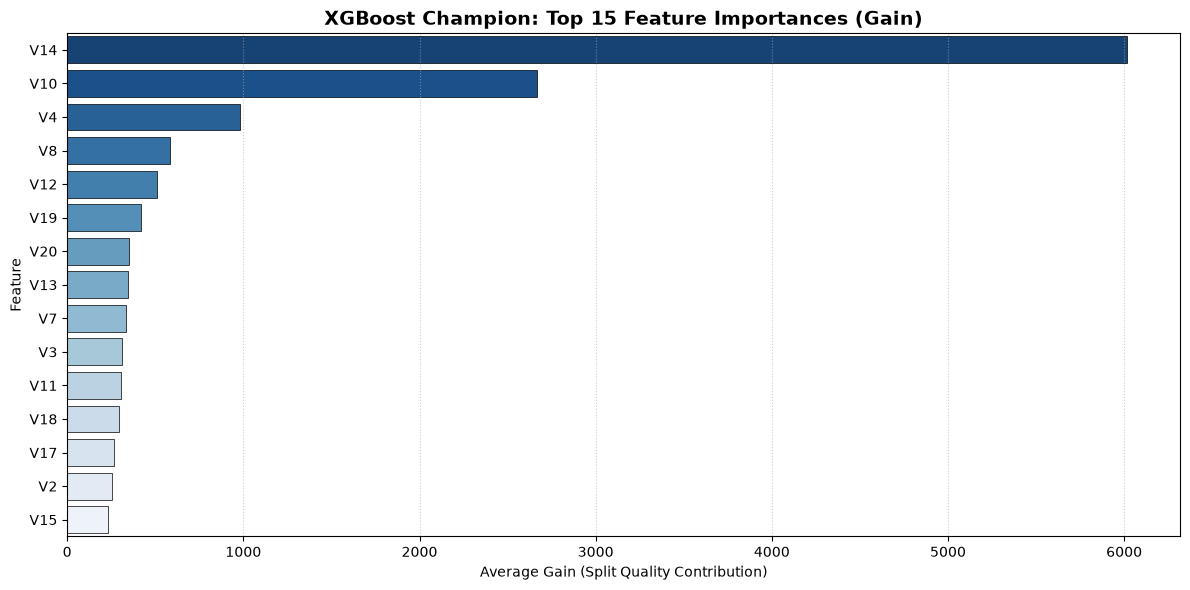

In [11]:
# 1. Extract feature importances based on Gain (predictive power)
importance_gain = xgb_clf.get_booster().get_score(importance_type='gain')
importance_df = pd.DataFrame({
    'Feature': list(importance_gain.keys()),
    'Gain': list(importance_gain.values())
}).sort_values(by='Gain', ascending=False).reset_index(drop=True)

# 2. Display Top 10 Most Influential Features
print("=" * 60)
print("       TOP 10 FRAUD DETECTION DRIVERS (BY GAIN)")
print("=" * 60)
display(importance_df.head(10))

# 3. Barplot of Top 15 Most Important Features
plt.figure(figsize=(12, 6))
top_15 = importance_df.head(15)
sns.barplot(
    x='Gain', 
    y='Feature', 
    data=top_15, 
    palette='Blues_r', 
    hue='Feature', 
    legend=False, 
    edgecolor='black', 
    linewidth=0.5
)
plt.title("XGBoost Champion: Top 15 Feature Importances (Gain)", fontsize=14, fontweight='bold')
plt.xlabel("Average Gain (Split Quality Contribution)")
plt.ylabel("Feature")
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 12: Model Serialization & Configuration Export

In [12]:
import json
import joblib

# 1. Resolve models directory
models_dir = 'models' if os.path.exists('models') else '../models'
os.makedirs(models_dir, exist_ok=True)

# 2. Save champion XGBoost model (both native JSON and Joblib formats)
xgb_json_path = os.path.join(models_dir, 'xgb_fraud_detector.json')
xgb_joblib_path = os.path.join(models_dir, 'xgb_fraud_detector.joblib')

xgb_clf.save_model(xgb_json_path)
joblib.dump(xgb_clf, xgb_joblib_path)

# 3. Export deployment metadata & operational thresholds
metadata = {
    'model_name': 'XGBoost Classifier',
    'evaluation_metrics': {
        'pr_auc': round(float(leaderboard_df.loc['XGBoost', 'PR-AUC']), 4),
        'roc_auc': round(float(leaderboard_df.loc['XGBoost', 'ROC-AUC']), 4),
        'f1_score_default': round(float(leaderboard_df.loc['XGBoost', 'F1-Score']), 4),
        'recall_default': round(float(leaderboard_df.loc['XGBoost', 'Recall (Fraud)']), 4),
        'precision_default': round(float(leaderboard_df.loc['XGBoost', 'Precision (Fraud)']), 4)
    },
    'operational_thresholds': {
        'default': 0.5,
        'cost_optimal': round(float(opt_cost['Threshold']), 3),
        'f1_optimal': round(float(opt_f1['Threshold']), 3),
        'f2_optimal': round(float(opt_f2['Threshold']), 3)
    },
    'cost_parameters': {
        'cost_fn_usd': COST_FN,
        'cost_fp_usd': COST_FP,
        'min_financial_loss_usd': round(float(opt_cost['Total_Cost']), 2)
    },
    'top_5_predictive_features': importance_df['Feature'].head(5).tolist()
}

meta_path = os.path.join(models_dir, 'model_metadata.json')
with open(meta_path, 'w') as f:
    json.dump(metadata, f, indent=4)

# 4. Verification and file summaries
print("=" * 65)
print("     PRODUCTION MODEL ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 65)
print(f"Native Model File:   {xgb_json_path} ({os.path.getsize(xgb_json_path)/1024:.1f} KB)")
print(f"Joblib Model File:   {xgb_joblib_path} ({os.path.getsize(xgb_joblib_path)/1024:.1f} KB)")
print(f"Model Metadata File: {meta_path} ({os.path.getsize(meta_path)} bytes)")
print("=" * 65)

# Preview exported metadata
with open(meta_path, 'r') as f:
    print(f.read())

     PRODUCTION MODEL ARTIFACTS SAVED SUCCESSFULLY
Native Model File:   ../models\xgb_fraud_detector.json (567.8 KB)
Joblib Model File:   ../models\xgb_fraud_detector.joblib (419.6 KB)
Model Metadata File: ../models\model_metadata.json (658 bytes)
{
    "model_name": "XGBoost Classifier",
    "evaluation_metrics": {
        "pr_auc": 0.8209,
        "roc_auc": 0.9766,
        "f1_score_default": 0.837,
        "recall_default": 0.8105,
        "precision_default": 0.8652
    },
    "operational_thresholds": {
        "default": 0.5,
        "cost_optimal": 0.182,
        "f1_optimal": 0.798,
        "f2_optimal": 0.552
    },
    "cost_parameters": {
        "cost_fn_usd": 150.0,
        "cost_fp_usd": 3.0,
        "min_financial_loss_usd": 2658.0
    },
    "top_5_predictive_features": [
        "V14",
        "V10",
        "V4",
        "V8",
        "V12"
    ]
}
